# Mini projeto — Regressão via RBF (Gaussianas).

**Definição do Problema:** aprender a **curva de potência** de uma turbina eólica — potência elétrica (kW) em função da velocidade do vento (m/s) — e utilizá-la para identificar horas em que a turbina produziu menos do que o esperado.

Dados horários reais de uma turbina Fuhrländer FL2500 de 2,5 MW (turbina 80), referentes a 2012, incluindo seu registro de alarmes
(fonte: [github.com/alecuba16/fuhrlander](https://github.com/alecuba16/fuhrlander), EPL-2.0).

### Etapas:
1. Examinar os dados
2. Construir atributos RBF gaussianos com **centros e σ escolhidos manualmente**
3. Treinar usando a **equação normal**
4. Treinar usando **descida do gradiente** — e verificar se obtemos a mesma resposta
5. Observar o que acontece ao alterar σ e o número de centros
6. Utilizar o modelo para detectar operação anormal


## 1. Dados
Cada linha representa uma hora: velocidade média do vento, potência média e indicação de que um **alarme de parada** do registro da turbina esteve ativo durante aquela hora. Para o treinamento, usamos apenas horas sem alarmes de parada ("operação normal").

Na maioria das horas, os ventos são moderados; ventos fortes são raros. Uma amostragem puramente aleatória deixaria pouquíssimos pontos de treinamento em velocidades elevadas, obrigando o modelo a fazer estimativas nessa região. Por isso, selecionamos uma amostra **estratificada**: 6 horas aleatórias de cada intervalo de velocidade do vento de 1 m/s (≈ 110 pontos, fáceis de visualizar em um gráfico). Todos os demais dados compõem o conjunto de teste.


8674 horas em 2012, 460 com um alarme de parada | treinamento 109, teste 8105


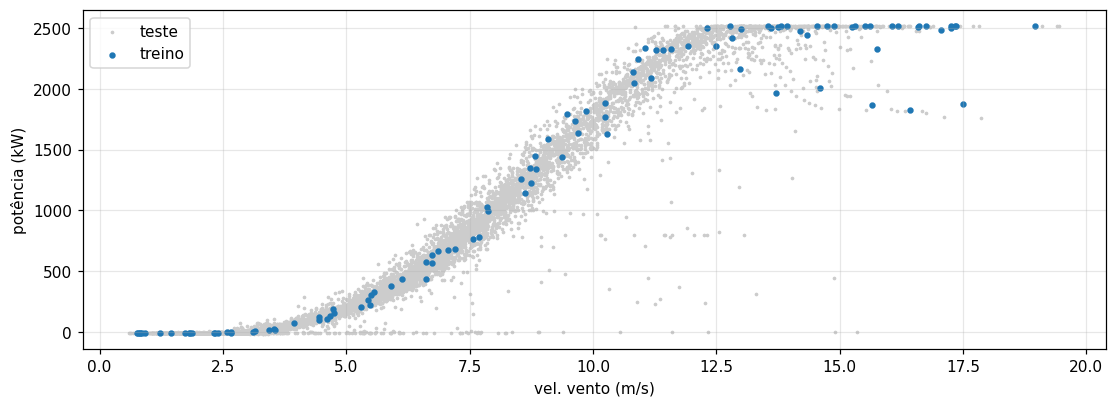

In [22]:
import numpy as np
from numpy.linalg import pinv as pv
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("turbine80_2012_hourly.csv", parse_dates=["time"])
normal = df[~df.stop_alarm]

rng = np.random.default_rng(0)
normal = normal.reset_index(drop = True)
wind_bin = np.floor(normal.wind_ms).astype(int)
tr_idx = np.concatenate([rng.permutation(np.where(wind_bin == b)[0])[:6] for b in range(19)])   # 6 por 1 m/s bin
train, test = normal.loc[tr_idx], normal.drop(tr_idx)
x_tr, y_tr = train.wind_ms.to_numpy(), train.power_kw.to_numpy()
x_te, y_te = test.wind_ms.to_numpy(), test.power_kw.to_numpy()
print(f"{len(df)} horas em 2012, {df.stop_alarm.sum()} com um alarme de parada | treinamento {len(x_tr)}, teste {len(x_te)}")

plt.figure(figsize=(12, 4))
plt.scatter(x_te, y_te, s = 2, c = "0.8", label = "teste")
plt.scatter(x_tr, y_tr, s = 10, c = "C0", label = "treino")
plt.xlabel("vel. vento (m/s)"); plt.ylabel("potência (kW)"); plt.legend(); plt.show()

**A clássica curva em S**: nenhuma produção abaixo de aproximadamente 3 m/s (velocidade de entrada em operação, *cut-in*), um crescimento acentuado (potência ∝ v³) e um patamar na potência nominal de 2500 kW, em que o ajuste do ângulo das pás limita a potência. Uma reta não consegue ajustar essa relação — mas uma soma de funções gaussianas consegue.

## 2. O modelo
$$
\hat y(x) = w_0 + \sum_{j=1}^{M} w_j\,\phi_j(x), \qquad
\phi_j(x) = \exp\!\left(-\frac{(x-c_j)^2}{2\sigma^2}\right)
$$

* $c_j$: **centros** — onde cada função gaussiana está posicionada (escolhidos manualmente)
* $\sigma$: **largura** — quão larga é cada função gaussiana (escolhida manualmente)
* $w_j$: **pesos** — aprendidos a partir dos dados

O modelo é não linear em $x$, mas **linear em $\mathbf w$**. Ao organizar os atributos dos $N$ pontos de treinamento, obtemos a matriz de projeto $\Phi$ (dimensão $N\times(M+1)$, primeira coluna = 1) e $\hat{\mathbf y} = \Phi\mathbf w$.


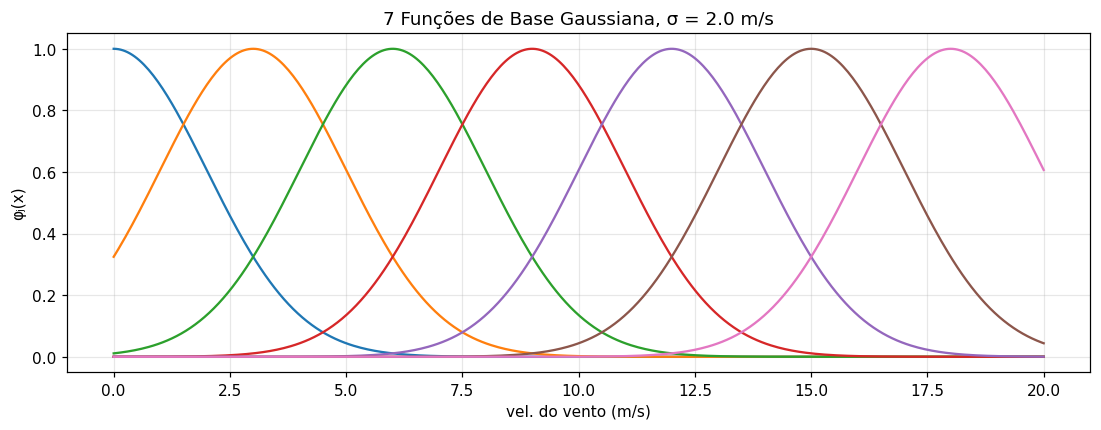

**Regra prática para a escolha manual:** distribua os centros ao longo do intervalo onde há dados e escolha $\sigma$ pela ordem do espaçamento entre centros vizinhos, para que as funções gaussianas se sobreponham sem se tornarem praticamente iguais.

## 3. Treinamento com a equação normal
Minimizamos o erro médio quadrático $J(\mathbf w) = \frac1N\lVert\Phi\mathbf w - \mathbf y\rVert^2$. Igualando o gradiente a zero:
$$
\nabla J = \frac{2}{N}\Phi^\top(\Phi\mathbf w-\mathbf y) = 0
\quad\Longrightarrow\quad
\boxed{\Phi^\top\Phi\,\mathbf w = \Phi^\top\mathbf y}
$$
Uma única resolução de sistema linear, sem iterações (`np.linalg.pinv`; nunca calcule explicitamente a inversa).


pesos: [ 2460.9 -1752.  -1412.3 -1417.8  -617.7   161.8  -120.4    10.6]
treino RMSE = 136 kW,  teste RMSE = 160 kW


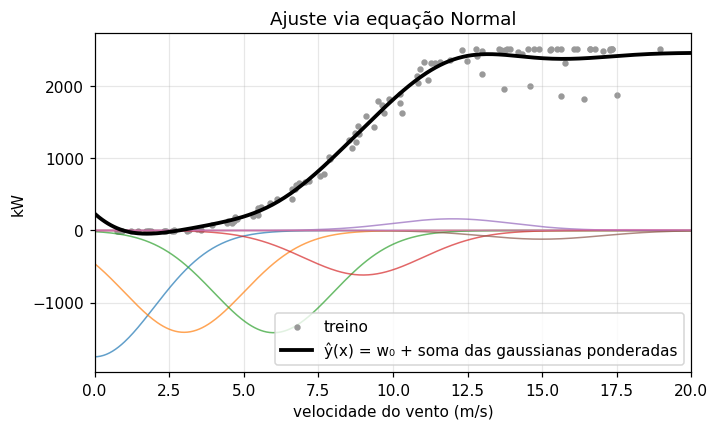

## 4. Treinamento com o gradiente descendente
Mesma função custo, mas com solução iterativa:
$$
\mathbf w \leftarrow \mathbf w - \eta\,\nabla J(\mathbf w), \qquad \nabla J = \frac{2}{N}\Phi^\top(\Phi\mathbf w-\mathbf y)
$$
**Escolha da taxa de aprendizado.** A função custo tem a forma de uma superfície quadrática convexa, com Hessiana $H=\frac2N\Phi^\top\Phi$. A descida do gradiente só converge se $\eta < 2/\lambda_{\max}(H)$; $\eta = 1/\lambda_{\max}$ é uma escolha inicial segura.


λmax = 2.820 → η = 0.355 (diverge acima 0.709);  condicionamente λmax/λmin = 8488


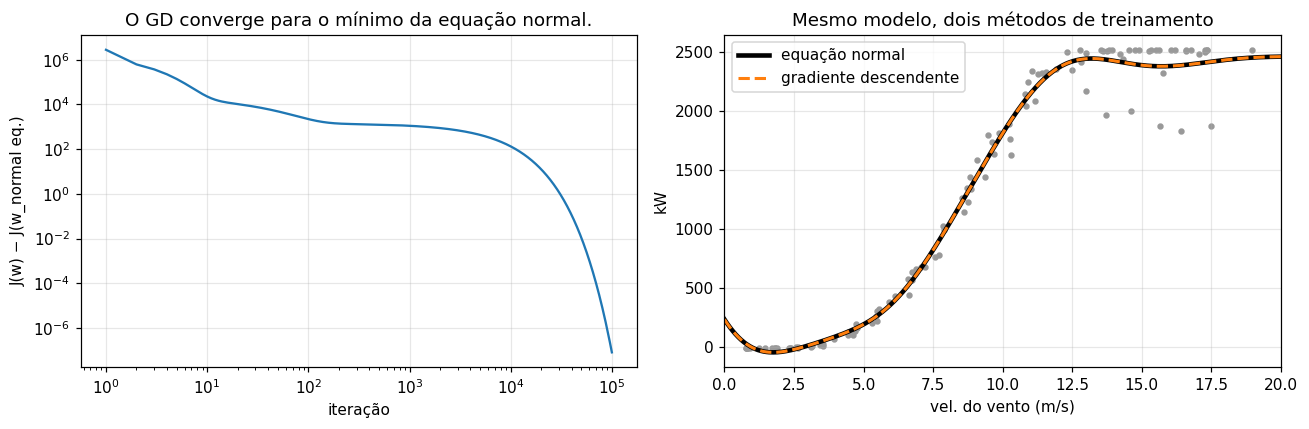

normal eq.: [ 2460.9 -1752.  -1412.3 -1417.8  -617.7   161.8  -120.4    10.6]
grad. desc: [ 2460.9 -1751.9 -1412.3 -1417.8  -617.7   161.8  -120.4    10.6]


## 5. Escolha manual de σ e dos centros
### 5.1 A largura σ (os mesmos 7 centros)


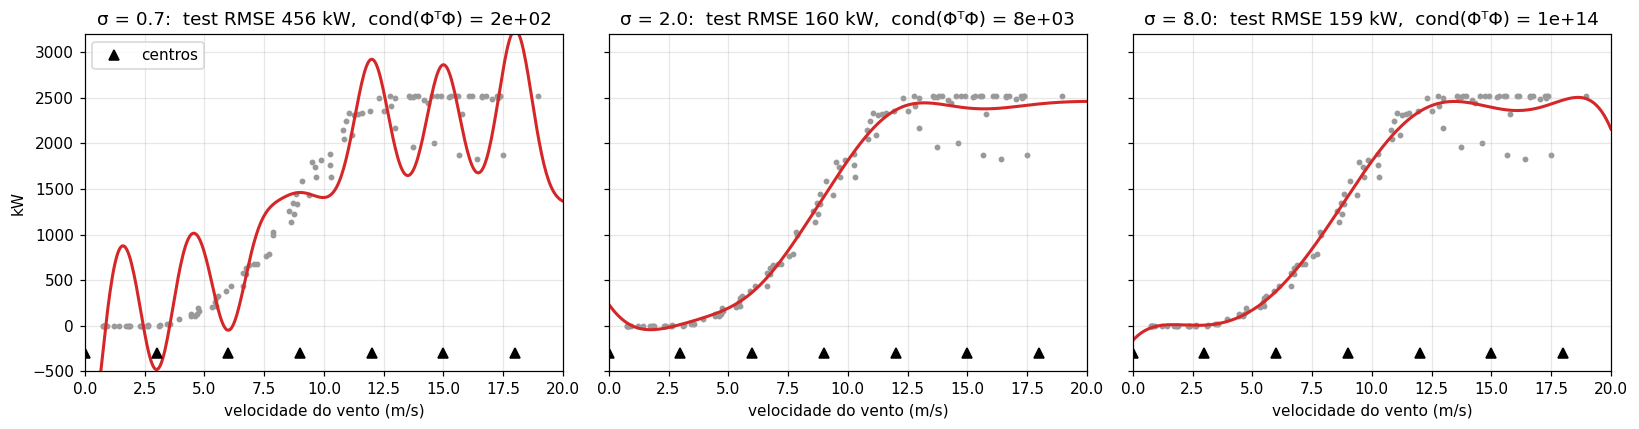

In [14]:
def fit_and_score(centros, sigma):
    P = rbf_features(x_tr, centros, sigma)
    w = np.linalg.lstsq(P, y_tr, rcond=None)[0]           # lstsq: robusto mesmo quando  PᵀP is praticamente singular
    return w, rmse(y_tr, P @ w), rmse(y_te, rbf_features(x_te, centros, sigma) @ w), np.linalg.cond(P.T @ P)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, s in zip(axs, [0.7, 2.0, 8.0]):
    w, e_tr, e_te, cond = fit_and_score(centros, s)
    ax.scatter(x_tr, y_tr, s=8, c="0.6")
    ax.plot(xg, rbf_features(xg, centros, s) @ w, "C3", lw=2)
    ax.plot(centros, np.full_like(centros, -300), "k^", label="centros")
    ax.set(title=f"σ = {s}:  test RMSE {e_te:.0f} kW,  cond(ΦᵀΦ) = {cond:.0e}", xlabel="velocidade do vento (m/s)",
           xlim=(0, 20), ylim=(-500, 3200))
axs[0].set_ylabel("kW"); axs[0].legend(); plt.tight_layout(); plt.show()

* **σ muito pequeno:** as funções gaussianas não se sobrepõem — a curva apresenta depressões entre os centros.
* **σ ≈ espaçamento:** curva suave que acompanha os dados.
* **σ muito grande:** todas as funções gaussianas ficam parecidas (as colunas de $\Phi$ tornam-se quase idênticas), $\Phi^\top\Phi$ fica quase singular (número de condição enorme), os pesos tornam-se muito grandes e instáveis, e a descida do gradiente seria extremamente lenta.

### 5.2 O número de centros M (σ = espaçamento entre centros)


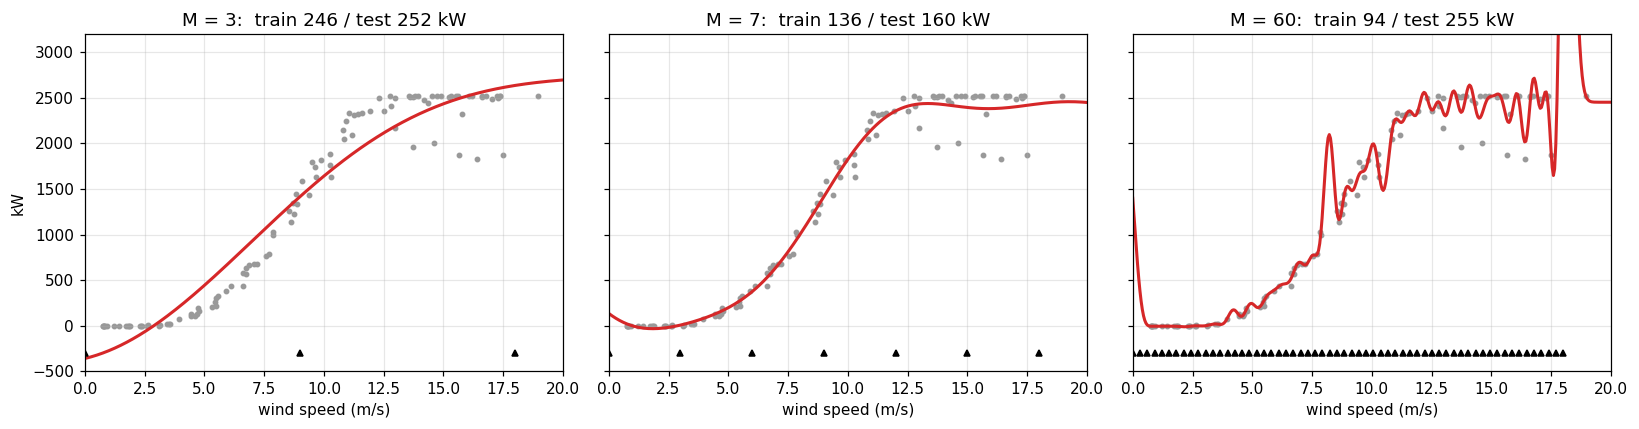

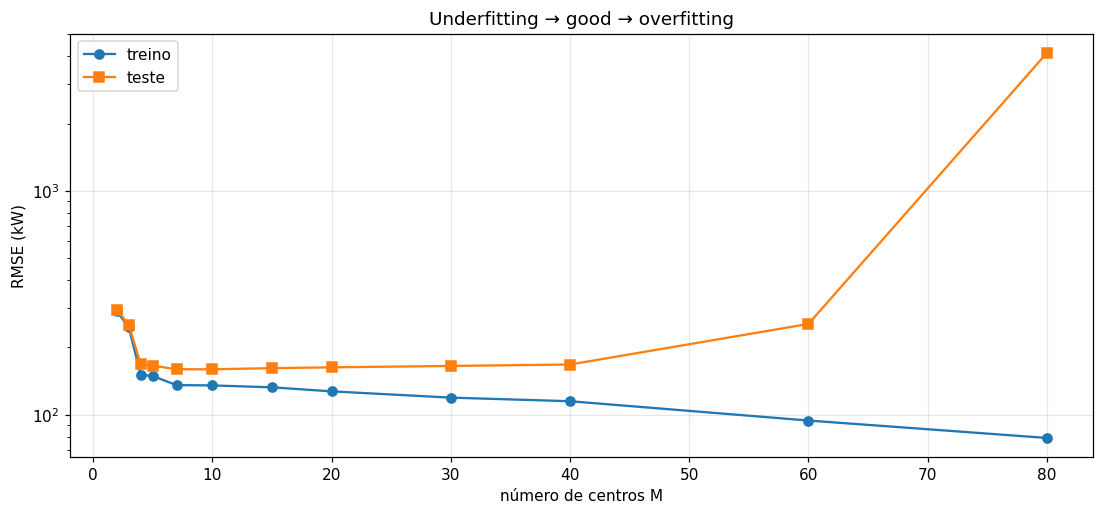

In [23]:
def grid(M):                                   # M centros uniformemente espaçados ao longo da faixa de dados
    c = np.linspace(0, 18, M)
    return c, c[1] - c[0]

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, M in zip(axs, [3, 7, 60]):
    c, s = grid(M)
    w, e_tr, e_te, _ = fit_and_score(c, s)
    ax.scatter(x_tr, y_tr, s=8, c="0.6")
    ax.plot(xg, rbf_features(xg, c, s) @ w, "C3", lw=2)
    ax.plot(c, np.full_like(c, -300), "k^", ms=4)
    ax.set(title=f"M = {M}:  train {e_tr:.0f} / test {e_te:.0f} kW", xlabel="wind speed (m/s)", xlim=(0, 20), ylim=(-500, 3200))
axs[0].set_ylabel("kW"); plt.tight_layout(); plt.show()

Ms = [2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 60, 80]
errs = np.array([fit_and_score(*grid(M))[1:3] for M in Ms])
plt.figure(figsize=(12, 5))
plt.plot(Ms, errs[:, 0], "o-", label="treino"); plt.plot(Ms, errs[:, 1], "s-", label="teste")
plt.yscale("log"); plt.xlabel("número de centros M"); plt.ylabel("RMSE (kW)"); plt.legend()
plt.title("Underfitting → good → overfitting"); plt.show()

* **Poucos centros:** a curva não consegue se ajustar suficientemente (subajuste, *underfitting*) — erros de treinamento e de teste elevados.
* **Centros demais** para ~110 pontos: a curva passa a acompanhar o ruído e apresenta oscilações extremas onde há poucos dados (ventos fortes) — o erro de treinamento continua diminuindo, mas o erro de teste aumenta (sobreajuste, *overfitting*).
* Escolha o modelo mais simples cujo erro de teste (preferencialmente, de *validação*) esteja próximo do mínimo.

## 6. Uso do modelo: detecção de operação anormal
A curva ajustada informa quanta potência a turbina **deveria** produzir para cada velocidade do vento. Agora, aplicamos o modelo a **todas** as horas de 2012, inclusive às que não foram utilizadas anteriormente. O resíduo $r = y - \hat y$ é fortemente negativo quando a turbina produz muito menos do que o esperado — por parada, falha ou redução da potência disponível. Regra: sinalizar uma hora quando $r <  \pm 2\,\hat\sigma_r$ (sendo $\hat\sigma_r$ o desvio-padrão dos resíduos nos dados de treinamento) e o vento estiver acima da velocidade de entrada em operação (4 m/s).


desvio padrão residual nos dados de treinamento: 136 kW  → threshold -408 kW
horas sinalizadas pelo modelo:          199
  ...que contava com um alarme de parada:      70
horas com um alarme de parada (vento > 4):  357  → captado pelo modelo: 20%


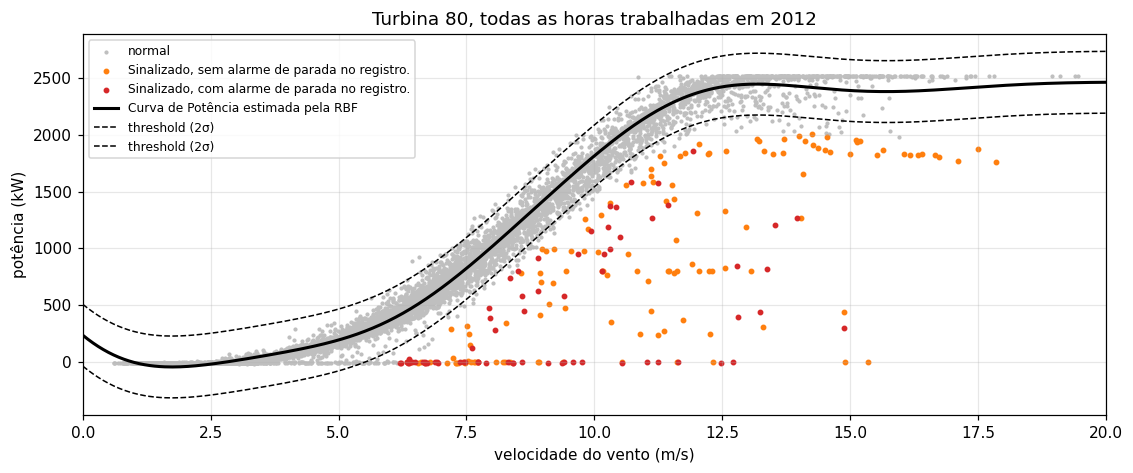

In [12]:
x_all, y_all = df.wind_ms.to_numpy(), df.power_kw.to_numpy()
r_all = y_all - rbf_features(x_all, centros, sigma) @ w_ne
sd_r = np.std(y_tr - Phi_tr @ w_ne)
flag = (r_all < -3 * sd_r) & (x_all > 4)
alarm = df.stop_alarm.to_numpy() & (x_all > 4)

print(f"desvio padrão residual nos dados de treinamento: {sd_r:.0f} kW  → threshold {-3*sd_r:.0f} kW")
print(f"horas sinalizadas pelo modelo:          {flag.sum()}")
print(f"  ...que contava com um alarme de parada:      {(flag & alarm).sum()}")
print(f"horas com um alarme de parada (vento > 4):  {alarm.sum()}  → captado pelo modelo: {(flag & alarm).sum() / alarm.sum():.0%}")

plt.figure(figsize=(12, 4.5))
plt.scatter(x_all[~flag], y_all[~flag], s = 3, c = "0.75", label = "normal")
plt.scatter(x_all[flag & ~alarm], y_all[flag & ~alarm], s = 8, c = "C1", label = "Sinalizado, sem alarme de parada no registro.")
plt.scatter(x_all[flag & alarm], y_all[flag & alarm], s = 8, c = "C3", label = "Sinalizado, com alarme de parada no registro.")
plt.plot(xg, G @ w_ne, "k", lw = 2, label = "Curva de Potência estimada pela RBF")
plt.plot(xg, G @ w_ne + 2 * sd_r, "k--", xg, G @ w_ne - 2 * sd_r, "k--", lw = 1, label = "threshold (2σ)")
plt.xlim(0, 20); plt.xlabel("velocidade do vento (m/s)"); plt.ylabel("potência (kW)"); plt.legend(fontsize=8)
plt.title("Turbina 80, todas as horas trabalhadas em 2012"); plt.show()

**Interpretação do resultado.**
* Vermelho: o modelo e o registro de alarmes concordam — a turbina estava parada ou apresentava falha naquela hora.
* Laranja: potência muito abaixo da curva **sem** alarme de parada — geralmente paradas durante parte da hora, restrição de geração (*curtailment*) ou redução da potência nominal (*derating*), por exemplo, para atender à rede elétrica ou devido a temperaturas elevadas. São precisamente as horas que um engenheiro de desempenho deve examinar.
* Os alarmes de parada não detectados pelo modelo correspondem, em sua maioria, a horas em que a parada durou apenas alguns minutos, de modo que a potência média horária permaneceu próxima do normal.

Um modelo de regressão do comportamento *normal* combinado com um limiar aplicado aos resíduos constitui a ideia central de muitos sistemas de monitoramento de condição.

## Exercícios
1. Posicione os centros de forma **não uniforme**, por exemplo, concentrando mais centros próximo à região de transição da curva (10–13 m/s). É possível obter o mesmo erro de teste com menos centros?
2. Com os 7 centros, represente graficamente o RMSE de teste em função de σ, de 0,5 a 8. Onde ocorre o mínimo? Compare-o com o espaçamento.
3. Execute a descida do gradiente com σ = 4. Quantas iterações são necessárias e por quê? (Dica: número de condição.)
4. Adicione uma penalização ridge: $(\Phi^\top\Phi + N\lambda I)\mathbf w = \Phi^\top\mathbf y$. Use-a para recuperar o modelo com M = 60.
5. Treine usando **todas** as horas normais, em vez de ~110. O modelo com M = 60 ainda apresenta sobreajuste? Por quê?
6. Substitua a amostra estratificada por 110 horas inteiramente aleatórias. O que acontece com a curva acima de 13 m/s e por quê?
7. Altere o limiar de detecção (−2σ, −4σ). Como mudam as quantidades de pontos vermelhos e laranjas?
